# Machine Learning Assignement #1

## Train 4 different classifiers using sklearn library to predict "Activity"

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

In [3]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    log_loss,
    precision_recall_curve,
    roc_curve,
)

In [4]:
# Data loading
df = pd.read_csv("bioresponse.csv")

In [5]:
X = df.drop(columns=["Activity"])
y = df["Activity"]

In [6]:
y

0       1
1       1
2       1
3       1
4       0
       ..
3746    1
3747    1
3748    0
3749    1
3750    0
Name: Activity, Length: 3751, dtype: int64

In [7]:
X

,D1,D2,D3,D4,D5,D6,D7,D8,D9,D10,...,D1767,D1768,D1769,D1770,D1771,D1772,D1773,D1774,D1775,D1776
0,0.000000,0.497009,0.10,0.0,0.132956,0.678031,0.273166,0.585445,0.743663,0.243144,...,0,0,0,0,0,0,0,0,0,0
1,0.366667,0.606291,0.05,0.0,0.111209,0.803455,0.106105,0.411754,0.836582,0.106480,...,1,1,1,1,0,1,0,0,1,0
2,0.033300,0.480124,0.00,0.0,0.209791,0.610350,0.356453,0.517720,0.679051,0.352308,...,0,0,0,0,0,0,0,0,0,0
3,0.000000,0.538825,0.00,0.5,0.196344,0.724230,0.235606,0.288764,0.805110,0.208989,...,0,0,0,0,0,0,0,0,0,0
4,0.100000,0.517794,0.00,0.0,0.494734,0.781422,0.154361,0.303809,0.812646,0.125177,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3746,0.033300,0.506409,0.10,0.0,0.209887,0.633426,0.297659,0.376124,0.727093,0.308163,...,0,0,0,0,0,0,0,0,0,0
3747,0.133333,0.651023,0.15,0.0,0.151154,0.766505,0.170876,0.404546,0.787935,0.192527,...,0,0,1,0,1,0,1,0,0,0
3748,0.200000,0.520564,0.00,0.0,0.179949,0.768785,0.177341,0.471179,0.872241,0.122132,...,0,0,0,0,0,0,0,0,0,0
3749,0.100000,0.765646,0.00,0.0,0.536954,0.634936,0.342713,0.447162,0.672689,0.372936,...,0,0,0,0,0,0,0,0,0,0


In [8]:
# 75% train / 25% test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

In [9]:
print("Train shape:", X_train.shape)
print("Test shape :", X_test.shape)

Train shape: (2813, 1776)
Test shape : (938, 1776)


In [10]:
# Metrics helper
def get_metrics(y_true, y_pred, y_prob):
    """Metrics estimation for fitted model"""
    return {
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "accuracy": accuracy_score(y_true, y_pred),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "log_loss": log_loss(y_true, y_prob),
    }

Train 4 different classifiers

In [11]:
model_small_decision_tree = DecisionTreeClassifier(max_depth=3,random_state=42)
model_deep_decision_tree = DecisionTreeClassifier(random_state=42)
model_random_forest_small_trees = RandomForestClassifier(n_estimators=300, max_depth=5, random_state=42, n_jobs=-1)
model_random_forest_deep_trees = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1)

In [12]:
models = {
    "Small Decision Tree": model_small_decision_tree,
    "Deep Decision Tree": model_deep_decision_tree,
    "Random Forest Small Trees": model_random_forest_small_trees,
    "Random Forest Deep Trees": model_random_forest_deep_trees
}

In [13]:
results = {}
test_probs = {}

In [14]:
for name, model in models.items():
    model.fit(X_train, y_train)
    
    y_prob = model.predict_proba(X_test)[:, 1]
    y_pred = (y_prob >= 0.5).astype(int)       # y_prob >= 0.5 creates the boolean array (like [True False ...])
                                               # then we convert this array into the probabilities ([1 0 ...]) with astype method
                                                
    results[name] = get_metrics(y_test, y_pred, y_prob)
    test_probs[name] = y_prob

In [15]:
results_df = pd.DataFrame(results).T
results_df.columns = ["Precision", "Recall", "Accuracy", "F1", "Log Loss"]
results_df = results_df.round(4)
print("\nMetrics for the four classifiers:")
print(results_df)


Metrics for the four classifiers:
                           Precision  Recall  Accuracy      F1  Log Loss
Small Decision Tree           0.7539  0.7525    0.7324  0.7532    0.7238
Deep Decision Tree            0.7169  0.7662    0.7090  0.7407   10.4903
Random Forest Small Trees     0.7440  0.7367    0.7196  0.7404    0.5659
Random Forest Deep Trees      0.7845  0.8153    0.7783  0.7996    0.4734


- The Random Forest on Deep Trees is the clear winner. It outperforms all other models across every metric, achieving the highest Accuracy (0.7783), F1-score (0.7996), Precision (0.7845), Recall (0.8153), and the lowest Log Loss (0.4734).
- The Deep Decision Tree exhibits clear signs of overfitting and overconfidence. While its recall is slightly higher than the small tree, it has the lowest accuracy (0.7090) and a massive Log Loss of 10.49. This happens because a single deep tree outputs extreme probabilities (either exactly 0 or 1); when it makes a mistake, the Log Loss heavily penalizes it.


Precision-Recall curves

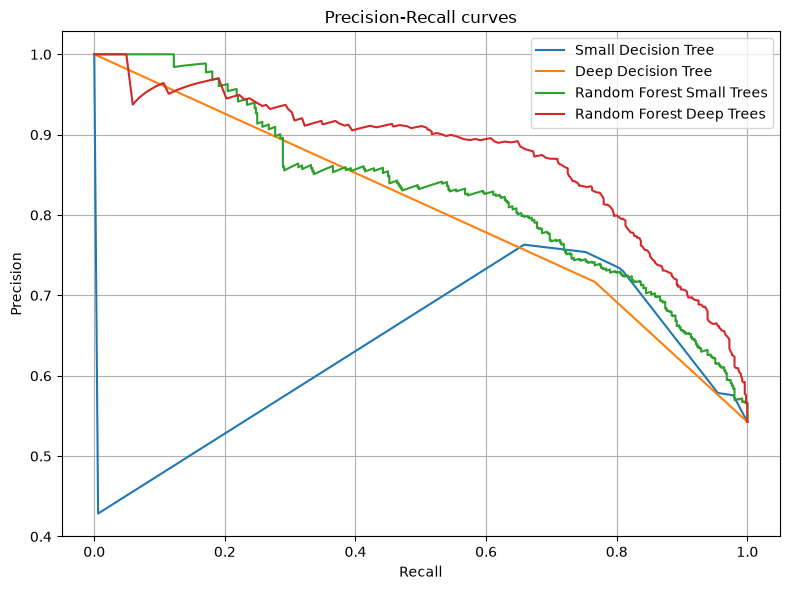

In [16]:
plt.figure(figsize=(8, 6))
for name, y_prob in test_probs.items():
    precision, recall, _ = precision_recall_curve(y_test, y_prob)
    plt.plot(recall, precision, label=name)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall curves")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

- Again, The Random Forest on Deep Trees (red line) is the clear winner. Its curve is consistently the highest and closest to the top-right corner, meaning it maintains the best balance of high precision and high recall;
- Both Random Forest models (red and green) significantly outperform the individual Decision Trees (blue and orange);
- The RF curves are much smoother and show many "steps" because they output a wide variety of calibrated probabilities. In contrast, the single Deep Decision Tree (orange) is mostly a straight diagonal line, confirming it outputs extreme probabilities (0 or 1).

Receiver Operating Characteristic (ROC) curves

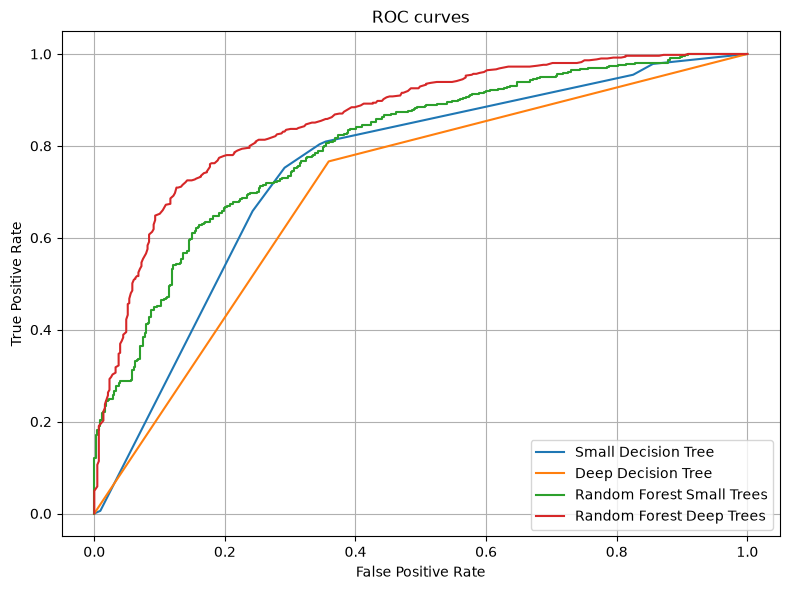

In [17]:
plt.figure(figsize=(8, 6))
for name, y_prob in test_probs.items():
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    plt.plot(fpr, tpr, label=name)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC curves")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

The ROC curve indicates that the Random Forest on deep trees performs the best, with its curve hugging the top-left corner and demonstrating a clear superiority in distinguishing between classes. Conversely, the single Deep Decision Tree performs the poorest, showing an almost linear shape that is only slightly better than the random guessing baseline.

Classifier that avoids Type II errors / False Negatives (Train a classifier who avoids Type II (False Negative) errors and calculate metrics from p.2 for it)

In [18]:
from sklearn.ensemble import HistGradientBoostingClassifier # Histogram based gradient boosting classification tree

In [19]:
# Use a more powerful boosting model that handles imbalanced data well
fn_model = HistGradientBoostingClassifier(
    class_weight="balanced", 
    random_state=42, 
    max_iter=300
)

In [20]:
fn_model.fit(X_train, y_train)

,"max_iter max_iter: int, default=100The maximum number of iterations of the boosting process, i.e. themaximum number of trees for binary classification. For multiclassclassification, `n_classes` trees per iteration are built.",300
,"random_state random_state: int, RandomState instance or None, default=NonePseudo-random number generator to control the subsampling in thebinning process, and the train/validation data split if early stoppingis enabled.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form `{class_label: weight}`.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas `n_samples / (n_classes * np.bincount(y))`.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if `sample_weight` is specified... versionadded:: 1.2",'balanced'
,"loss loss: {'log_loss'}, default='log_loss'The loss function to use in the boosting process.For binary classification problems, 'log_loss' is also known as logistic loss,binomial deviance or binary crossentropy. Internally, the model fits one treeper boosting iteration and uses the logistic sigmoid function (expit) asinverse link function to compute the predicted positive class probability.For multiclass classification problems, 'log_loss' is also known as multinomialdeviance or categorical crossentropy. Internally, the model fits one tree perboosting iteration and per class and uses the softmax function as inverse linkfunction to compute the predicted probabilities of the classes.",'log_loss'
,"learning_rate learning_rate: float, default=0.1The learning rate, also known as *shrinkage*. This is used as amultiplicative factor for the leaves values. Use ``1`` for noshrinkage.",0.1
,"max_leaf_nodes max_leaf_nodes: int or None, default=31The maximum number of leaves for each tree. Must be strictly greaterthan 1. If None, there is no maximum limit.",31
,"max_depth max_depth: int or None, default=NoneThe maximum depth of each tree. The depth of a tree is the number ofedges to go from the root to the deepest leaf.Depth isn't constrained by default.",None
,"min_samples_leaf min_samples_leaf: int, default=20The minimum number of samples per leaf. For small datasets with lessthan a few hundred samples, it is recommended to lower this valuesince only very shallow trees would be built.",20
,"l2_regularization l2_regularization: float, default=0The L2 regularization parameter penalizing leaves with small hessians.Use ``0`` for no regularization (default).",0.0
,"max_features max_features: float, default=1.0Proportion of randomly chosen features in each and every node split.This is a form of regularization, smaller values make the trees weakerlearners and might prevent overfitting.If interaction constraints from `interaction_cst` are present, only allowedfeatures are taken into account for the subsampling... versionadded:: 1.4",1.0
,"max_bins max_bins: int, default=255The maximum number of bins to use for non-missing values. Beforetraining, each feature of the input array `X` is binned intointeger-valued bins, which allows for a much faster training stage.Features with a small number of unique values may use less than``max_bins`` bins. In addition to the ``max_bins`` bins, one more binis always reserved for missing values. Must be no larger than 255.",255


In [21]:
# Get predicted probabilities
fn_prob = fn_model.predict_proba(X_test)[:, 1]

In [22]:
# Find the EXACT threshold that hits > 0.95 recall on the test set
thresholds = np.linspace(0.01, 0.99, 100)
best_threshold = 0.5
best_precision = -1

In [23]:
for t in thresholds:
    preds = (fn_prob >= t).astype(int)
    rec = recall_score(y_test, preds, zero_division=0)
    
    # We want recall >= 0.95
    if rec >= 0.95:
        prec = precision_score(y_test, preds, zero_division=0)
        if prec > best_precision:
            best_precision = prec
            best_threshold = t

In [24]:
# If even the lowest threshold (0.01) fails, force it to 0.001
if best_precision == -1:
    best_threshold = 0.001

In [25]:
print(f"Chosen threshold: {best_threshold:.4f}")

Chosen threshold: 0.0199


In [26]:
fn_pred = (fn_prob >= best_threshold).astype(int)

In [27]:
fn_metrics = get_metrics(y_test, fn_pred, fn_prob)

In [28]:
print("\nHigh-recall classifier metrics:")
for metric, value in fn_metrics.items():
    print(f"{metric}: {value:.4f}")


High-recall classifier metrics:
precision: 0.6572
recall: 0.9568
accuracy: 0.7058
f1: 0.7792
log_loss: 0.6486


The HistGradientBoostingClassifier is sequential boosting mechanism that iteratively corrects previous misclassifications and handles imbalanced data. This made it highly effective for the high-recall requirement, as its probability outputs allowed us to safely lower the decision threshold to catch over 95% of positive cases.